# Importing Libraries

In [195]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
import SOAP
from SOAP import PHOENIX
from SOAP import fast_starspot as stspnumba
import pandas as pd
from SOAP.SOAP import remove_units, without_units
from SOAP.classes import Spectrum

# Set Stellar Parameters

In [196]:
# Star-like star, rigid rotation
radius=1                # Stellar radius [solar radii]
mass=1                  # Stellar mass [solar masses]
prot=24.47              # Stellar rotation period [days]
incl=45                 # Stellar inclination [degrees] -> 90 is equator-on, 0 is pole-on
logg= 4.4               # Stellar surface gravity [cgs]
feh= 0.00               # Stellar metallicity [dex]
Teff=5777               # Stellar effective temperature [K]
ldcn=[0.5, 0.16]        # Linear and quadratic limb-darkening coefficients (must agree with λ, see below)
law=1                   # Limb-darkening law (quadratic)
start_psi=0.0           # Starting phase of the star

# Load in Bandpasses and Set Observational Parameters

## CHEOPS

In [197]:
# load in bandpass
bp_CHEOPS = np.array(pd.read_csv('CHEOPS_bandpass.csv')['PASSBAND'])
λ_bp_CHEOPS = np.array(pd.read_csv('CHEOPS_bandpass.csv')['WAVELENGTH'])

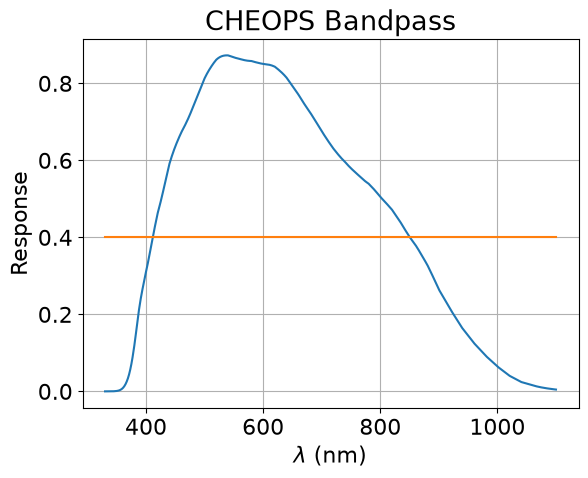

In [198]:
# plot bandpass
plt.plot(λ_bp_CHEOPS, bp_CHEOPS)
plt.plot(λ_bp_CHEOPS, np.linspace(0.4, 0.4, len(λ_bp_CHEOPS)))
plt.grid(True)
plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel('Response')
plt.title('CHEOPS Bandpass');

In [199]:
# Observational parameters 
λ_CHEOPS=[4000, 8500]    # Wavelength range [Angstrom] 

## TESS

In [200]:
# load in bandpass
bp_TESS = np.array(pd.read_csv('tess-response-function-v2.0.csv', skiprows=6)[' lambda Transmission'])
λ_bp_TESS = np.array(pd.read_csv('tess-response-function-v2.0.csv', skiprows=6)['# Wavelength (nm)'])

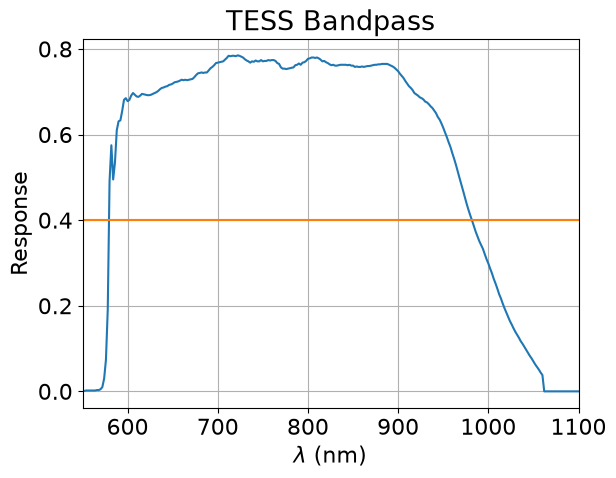

In [201]:
# plot bandpass
plt.plot(λ_bp_TESS, bp_TESS)
plt.plot(λ_bp_TESS, np.linspace(0.4, 0.4, len(λ_bp_TESS)))
plt.grid(True)
plt.xlabel(r'$\lambda$ (nm)')
plt.ylabel('Response')
plt.xlim(550, 1100)
plt.title('TESS Bandpass');

In [202]:
# Observational parameters 
λ_TESS=[6000, 10000]    # Wavelength range [Angstrom] 

# Set QS and AR Spectra

In [220]:
# generate spectra 
spQ_CHEOPS = PHOENIX(wave_range=λ_CHEOPS, normalize=False, teff=Teff, logg=logg, Z=feh) # stellar spectrum
spQ_ar_CHEOPS = PHOENIX(wave_range=λ_CHEOPS, normalize=False, teff=Teff, logg=logg, Z=feh, contrast=0, ar=True) # AR spectrum
spQ_TESS = PHOENIX(wave_range=λ_TESS, normalize=False, teff=Teff, logg=logg, Z=feh) # stellar spectrum
spQ_ar_TESS = PHOENIX(wave_range=λ_TESS, normalize=False, teff=Teff, logg=logg, Z=feh, contrast=0, ar=True) # AR spectrum

# convolve resolution down to more realistic instrumentation values 
Spectrum.convolve_to(spQ_CHEOPS, 50000, inplace=True)
Spectrum.convolve_to(spQ_ar_CHEOPS, 50000, inplace=True)
Spectrum.convolve_to(spQ_TESS, 50000, inplace=True)
Spectrum.convolve_to(spQ_ar_TESS, 50000, inplace=True)

# Simulate Stellar Spectra

## Create Function

In [204]:
def run_sim_spectra(λ, spQ, spQ_ar, grid, psi_f, d_psi):   
    
    # set resampling rate
    original = 500000/((λ_CHEOPS[1]+λ_CHEOPS[0])/2)
    new = (50000/((λ_CHEOPS[1]+λ_CHEOPS[0])/2))/3 # new resolution, sampling one delta lambda across 3 pixels
    resample = int(original/new)

    # create simulation variable  
    # wavelength for temperature contrast via Planck's law is median of above list
    sim = SOAP.Simulation(pixel=spQ, pixel_ar=spQ_ar, wlll=(λ[1]+λ[0])/2, grid=grid, active_regions=[], 
                          resample_spectra=resample)
                          # want to have same number of lambda values as in integer list

    # add active region at equator
    sim.active_regions=[SOAP.ActiveRegion(check=True, lon=180, lat=0, size=0.084, temp_diff=600, active_region_type=0)]

    # Set the properties of the star
    sim.star.set(prot=prot,incl=incl,coeffs=ldcn,law=law,start_psi=start_psi,radius=radius,mass=mass,teff=Teff)

    # remove planet, set long period so planet doesn't appear during simulation 
    sim.planet.Rp=0
    sim.planet.P = 1.0e6          # effectively stationary planet
    sim.planet.t0 = -0.75 * sim.planet.P
    sim.planet.e = 0.0
    sim.planet.w = 0.0
    sim.planet.ip = 90.0
    sim.planet.a = 0.05

    # Simulate over 3 stellar phases
    psi = np.linspace(0,psi_f,d_psi) 
    
    # remove ring
    sim.ring = SOAP.Ring(fi=1,fe=1,ir=90,theta=0)

    # Calculate spectra
    out=sim.calculate_signal(psi, renormalize_rv=True)
    
    return sim, out, psi

## CHEOPS

In [221]:
# set run params
grid = 5
psi_f = 3
d_psi = 6

# run simulation 
sim_spec_CHEOPS, out_spec_CHEOPS, psi_CHEOPS = run_sim_spectra(λ_CHEOPS, spQ_CHEOPS, spQ_ar_CHEOPS, grid, psi_f, d_psi)

In [206]:
print(sim_spec_CHEOPS.pixel_quiet)
#sim_spec_CHEOPS.active_regions = list(without_units(*sim_spec_CHEOPS.active_regions))
print(without_units(*sim_spec_CHEOPS.active_regions))
print(sim_spec_CHEOPS.wlll)
for ar in sim_spec_CHEOPS.active_regions:
    print(ar)
    print(ar.check)

[1.62418845e+16 1.63695939e+16 1.68145331e+16 ... 6.93690204e+15
 7.25557402e+15 7.35867145e+15]
ActiveRegion(lon=np.float64(180.0), lat=np.float64(0.0), size=0.084, check=True, coeffs=None, law=None, active_region_type=0, temp_diff=np.float64(600.0), size_area_visible_hemisphere=0.0035280000000000003, type='spot', random=<bound method ActiveRegion.random of <class 'SOAP.classes.ActiveRegion'>>, set=<bound method ActiveRegion.set of SOAP.ActReg(spot; lon=180.00 deg; lat=0.00 deg; size=0.08)>, get_size=<bound method ActiveRegion.get_size of SOAP.ActReg(spot; lon=180.00 deg; lat=0.00 deg; size=0.08)>)
6250.0
SOAP.ActReg(spot; lon=180.00 deg; lat=0.00 deg; size=0.08)
True


In [223]:
a = stspnumba.active_region_contributions(psi_CHEOPS, 
                                           without_units(sim_spec_CHEOPS.star), 
                                           sim_spec_CHEOPS.active_regions, 
                                           sim_spec_CHEOPS.pixel.to_numba(), 
                                           sim_spec_CHEOPS.pixel_ar.to_numba(), 
                                           sim_spec_CHEOPS.grid, 
                                           sim_spec_CHEOPS.nrho, 
                                           sim_spec_CHEOPS.wlll, 
                                           without_units(sim_spec_CHEOPS.planet),
                                           without_units(sim_spec_CHEOPS.ring), 
                                           ccf=False, 
                                           skip_rv=False)

print(np.where(np.array(a[3][1]) > 0))
print(a)

(array([], dtype=int64),)
(array([0., 0., 0., 0., 0., 0.]), array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(6, 17224)), array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(6, 17224)), array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(6, 17224)))


In [208]:
# save data 
with pd.ExcelWriter("CHEOPS_spectra_" + str(grid) + "_" + str(psi_f) + "_" + str(d_psi) + ".xlsx", engine="xlsxwriter") as writer: 
    for i in np.arange(0, len(sim_spec_CHEOPS.integrated_spectra), 1): # iterate through spectra at each psi value 
        # create data frame 
        df = pd.DataFrame(dict(zip(spQ_CHEOPS.wave[::int(len(spQ_CHEOPS.wave)/(λ_CHEOPS[1]-λ_CHEOPS[0]))], 
                          sim_spec_CHEOPS.integrated_spectra[i])), index=[0]).T
        df.to_excel(writer, sheet_name = str(round(psi_CHEOPS[i], 1)))

In [209]:
print(sim_spec_CHEOPS.pixel_tot, sim_spec_CHEOPS.integrated_spectra)

[[0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.8408429  0.84760268 0.87068771 ... 0.35946632 0.37598797 0.38130658]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.84082435 0.84758022 0.87064116 ... 0.35944522 0.37596912 0.381291  ]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]] [[0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.8408429  0.84760268 0.87068771 ... 0.35946632 0.37598797 0.38130658]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]
 [0.84082435 0.84758022 0.87064116 ... 0.35944522 0.37596912 0.381291  ]
 [0.84112647 0.84774022 0.8707825  ... 0.35924476 0.37574798 0.38108714]]


## TESS

In [210]:
# run simulation 
sim_spec_TESS, out_spec_TESS, psi_TESS = run_sim_spectra(λ_TESS, spQ_TESS, spQ_ar_TESS, grid, psi_f, d_psi)

In [211]:
# save data 
with pd.ExcelWriter("TESS_spectra_" + str(grid) + "_" + str(psi_f) + "_" + str(d_psi) + ".xlsx", engine="xlsxwriter") as writer: 
    for i in np.arange(0, len(sim_spec_TESS.integrated_spectra), 1): # iterate through spectra at each psi value 
        # create data frame 
        df = pd.DataFrame(dict(zip(spQ_CHEOPS.wave[::int(len(spQ_TESS.wave)/(λ_TESS[1]-λ_TESS[0]))], 
                          sim_spec_TESS.integrated_spectra[i])), index=[0]).T
        df.to_excel(writer, sheet_name = str(round(psi_TESS[i], 1)))

In [212]:
print(sim_spec_TESS.pixel_tot, sim_spec_TESS.integrated_spectra)

[[0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847677 0.99939741 0.9060888  ... 0.40472318 0.40531538 0.40346528]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847568 0.99940996 0.9060934  ... 0.40472487 0.40531517 0.40346512]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]] [[0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847677 0.99939741 0.9060888  ... 0.40472318 0.40531538 0.40346528]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]
 [0.99847568 0.99940996 0.9060934  ... 0.40472487 0.40531517 0.40346512]
 [0.99847762 0.99940356 0.90617415 ... 0.40455781 0.40514707 0.40330152]]
